In [1]:
import sys
import os
import numpy as np
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [3]:
organism = 'worm'

ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
manual = False
full = True

save = True

In [4]:
file_id = 19
neuron_labels = ['VB02', 'SMDDR', 'AVAR']

bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# generic

In [5]:
filename, traces, behavior, classes, aux = analysis_utils.read_data(organism, file_id)
model_path = read_utils.get_model_path()

metadata = (filename, model_path, model_variant, data_variant, manual, full)

neuron_labels = [label for label in neuron_labels if label in traces.columns]

# traces

In [6]:
bom_params, hgm_params = analysis_utils.read_models(*metadata)

((_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss),
 (_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss)) = analysis_utils.read_predictions(*metadata)

bom_manifolds, bom_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)
hgm_manifolds, hgm_manifold_vars_expl = analysis_utils.postprocess_manifold(bom_man, traces, bom_params)

In [7]:
# (pca_modes, _, _,
#  pca_vars_expl) = train_utils.get_manifolds_pca(
# 	[traces],
# 	scale=False, n_pc=hgm_man[0].values.shape[1])
# (cca_modes, _, _, _, _, _,
#  cca_vars_expl, cca_vars_expl_rs) = train_utils.get_manifolds_cca(
# 	[traces], [classes[bhl_selection]],
# 	scale=False, n_cv=hgm_man[0].values.shape[1], n_pc=classes[bhl_selection].values.shape[1])
# (plsc_modes, _, _, _, _, _,
#  plsc_vars_expl) = train_utils.get_manifolds_plsc(
# 	[traces], [classes[bhl_selection]],
# 	scale=False, n_ls=hgm_man[0].values.shape[1])

# traces by gating

In [8]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))
neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

In [9]:
hgm_man_zs = [(hgm_man[s].values - hgm_man[s].values.mean(axis=0)) / np.where((N_std := hgm_man[s].values.std(axis=0)) == 0.0, 1.0, N_std) for s in range(len(hgm_man))]
WMs = [hgm_params[s]['model']['WM'] for s in range(len(hgm_params))]
gating_term = [pd.DataFrame(sigmoid(hgm_man_zs[s] @ WMs[s]), columns=traces.columns) for s in range(len(hgm_man_zs))]

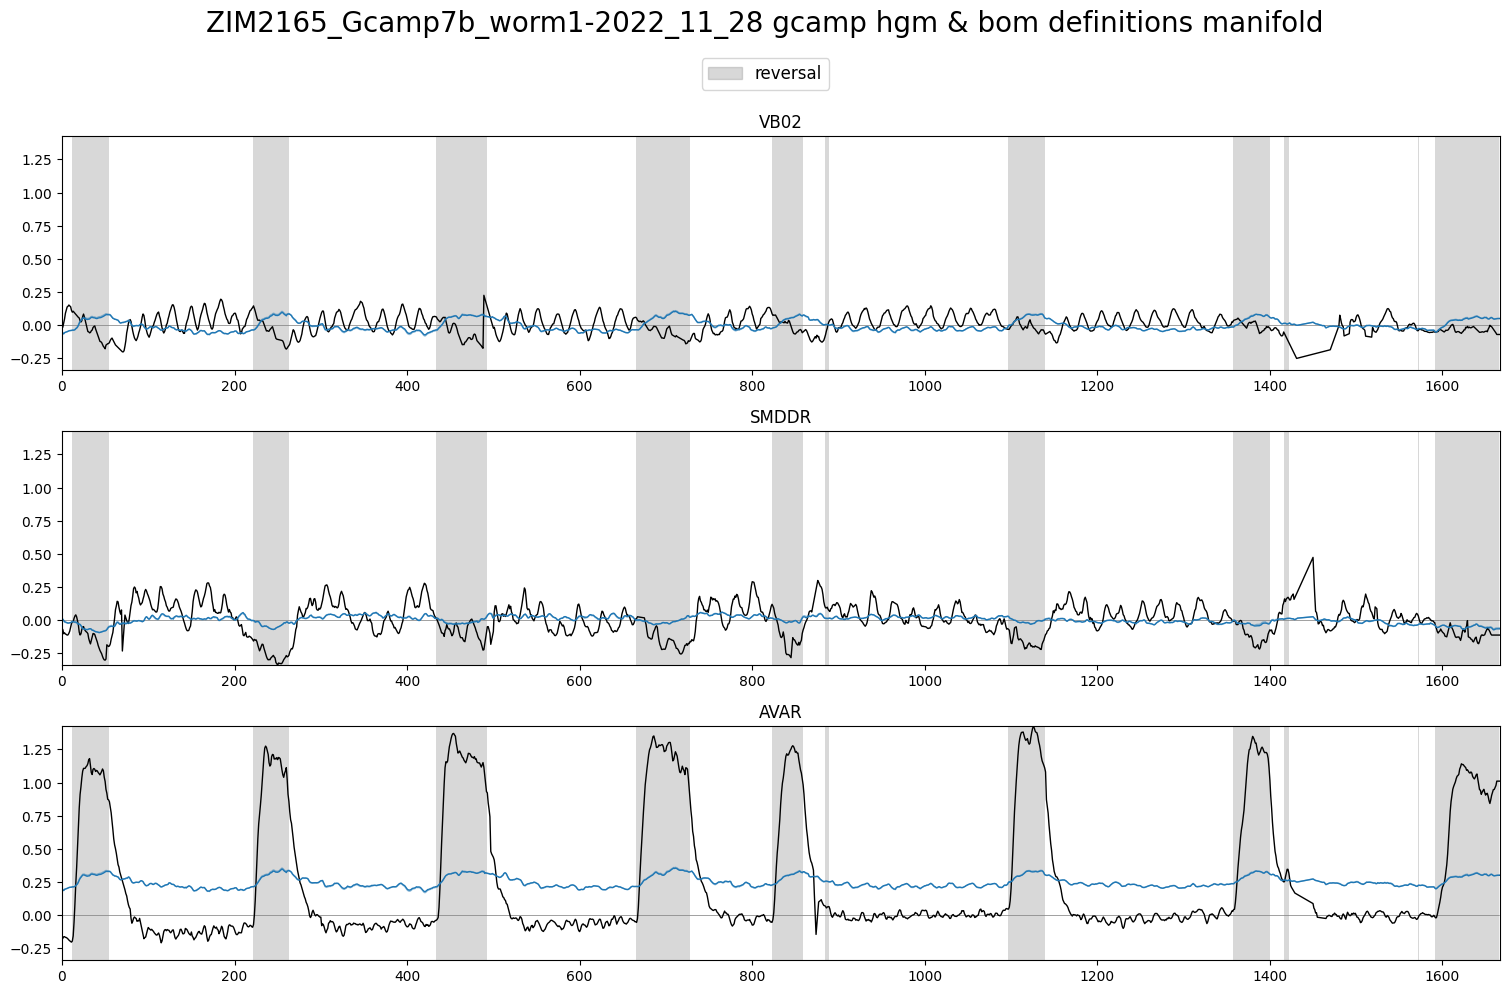

In [10]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	[bom_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_reconstructions' if save else None)

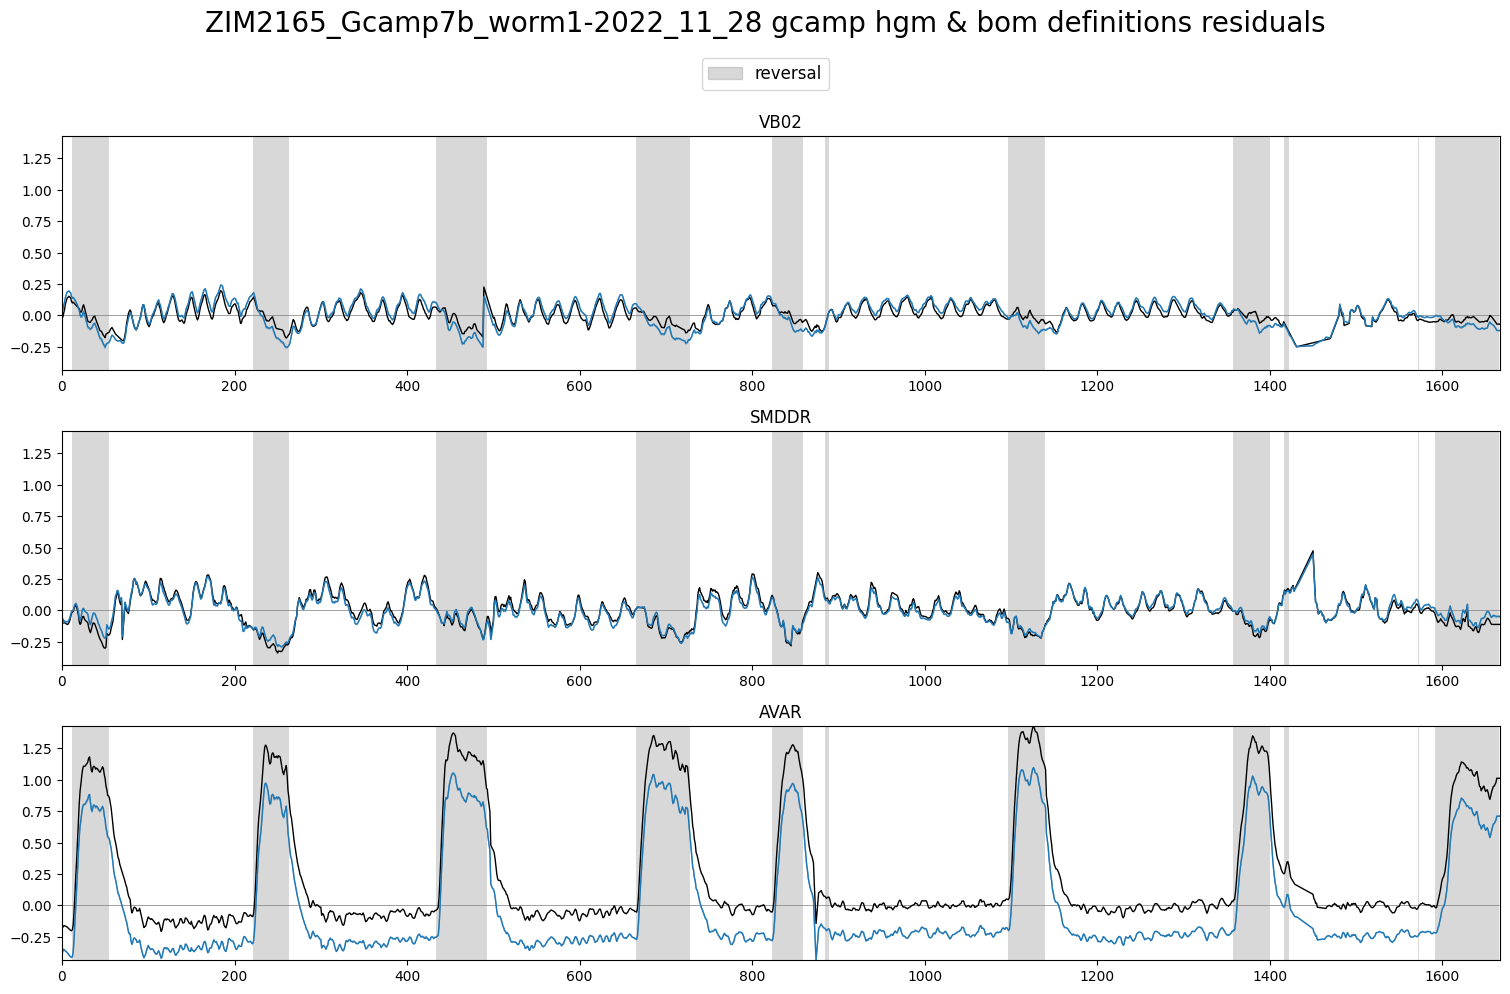

In [11]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_res[i].loc[:max_x, neuron_labels] for i in range(len(hgm_res))],
	[bom_res[i].loc[:max_x, neuron_labels] for i in range(len(hgm_res))],
	traces.loc[:max_x, neuron_labels],
	classes.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_residuals' if save else None)

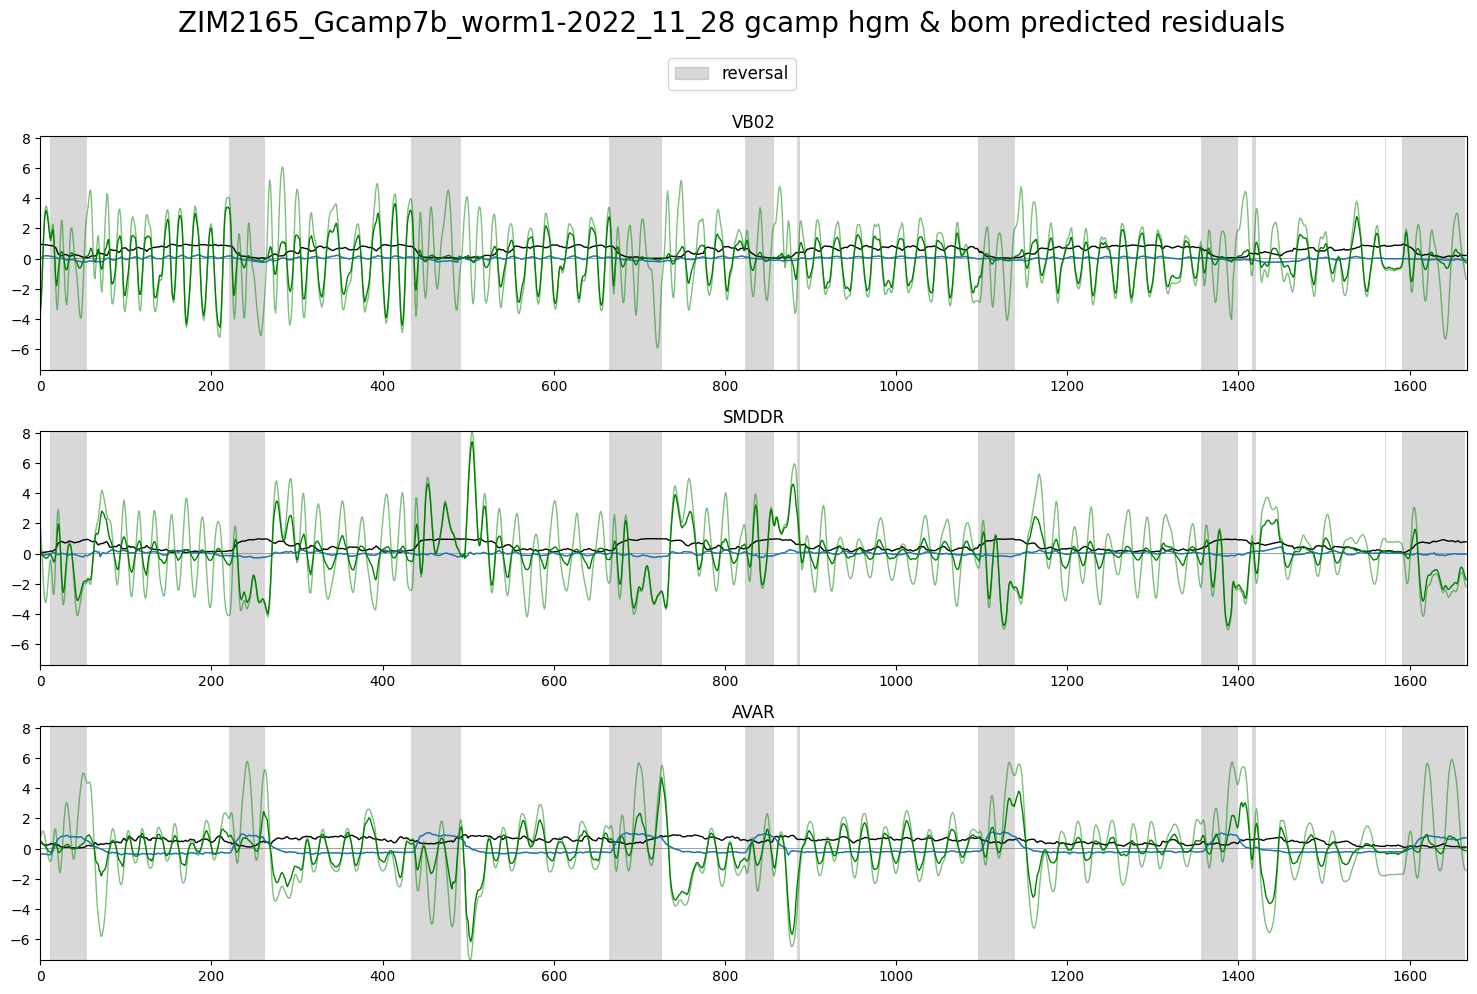

In [12]:
# max_x = 500
max_x = traces.values.shape[0]

for s in range(len(hgm_res)):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[s].loc[:max_x, neuron_labels],
		 hgm_pres[s].loc[:max_x, neuron_labels]],
		[bom_res[s].loc[:max_x, neuron_labels],
		 bom_pres[s].loc[:max_x, neuron_labels]],
		gating_term[s].loc[:max_x],
		classes.loc[:max_x, ['REV']], label='reversal',
		title=f'{filename} gcamp hgm & bom predicted residuals' + (f' s{s}' if len(hgm_res) > 1 else ''), ylimits=None, plots_per_row=1,
		save_path=f'../../out/plots/traces/{filename}/{model_variant}_model_predicted_residuals' + (f'_s{s}' if len(hgm_res) > 1 else '') if save else None)